# Step 6 — find the gate question of every high-missing feature from the data (analysis only)

For a feature F with missing ≥ 20% (not a checkbox, not a subsample lab, not empty in every cycle) and every candidate gate G in the same module (fewer missing than F, ≤ 20 distinct values), let S = the values of G after which F is answered at least half the time.

- **purity** = P(G in S | F answered): ~1 means F is only asked after G in S
- **coverage** = P(F answered | G in S): ~1 means everyone with G in S answers F

The gate is the G with the highest purity × coverage. F answered for people outside S cannot happen, so for them F is "not asked" rather than missing. Population and renames as in `step5_missing.ipynb`.

**Output:** `gates.csv` (module, variable, label, missing, gate, gate_label, gate_values, purity, coverage)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import io as nio  # noqa: E402
from nhanes.cohort import CYCLES, FAMILY, population  # noqa: E402
from nhanes.paths import WORK  # noqa: E402

SKIP_MODULES = {"GLU", "TRIGLY", "PFAS", "PFC", "OGTT"}


def pooled(module, names, old_of):
    frames = []
    for cycle in CYCLES:
        pop = population(cycle)[["SEQN"]]
        parts = [nio.read_component(m, cycle, required=False)
                 for m in [module] + [k for k, v in FAMILY.items() if v == module]]
        d = next(p for p in parts if p is not None)
        d = d.rename(columns={old: new for (m, new), old in old_of.items() if m == module})
        frames.append(pop.merge(d[["SEQN"] + [c for c in names if c in d]], on="SEQN", how="left"))
    return pd.concat(frames, ignore_index=True)


def best_gate(f, cands, d):
    answered = d[f].notna()
    best = None
    for g in cands:
        if g == f:
            continue
        s = pd.to_numeric(d[g], errors="coerce")
        rate = answered.groupby(s).mean()
        S = rate[rate >= 0.5].index
        if len(S) == 0 or answered.sum() == 0:
            continue
        in_s = s.isin(S)
        purity = in_s[answered].mean()
        coverage = answered[in_s].mean()
        if best is None or purity * coverage > best[1] * best[2]:
            best = (g, purity, coverage, sorted(S))
    return best

In [2]:
mr = pd.read_csv(WORK / "missing_rates.csv")
rmap = pd.read_csv(WORK / "rename_map.csv")
old_of = {(r.module, r.new): r.old for r in rmap.itertuples()}
labels = dict(zip(mr.variable, mr.label))
rows = []
for module, m in mr.groupby("module"):
    if module in SKIP_MODULES:
        continue
    targets = m[(m.missing_overall >= 0.2) & ~m.checkbox & (m.empty_cycles < 7)]
    if targets.empty:
        continue
    d = pooled(module, list(m.variable), old_of)
    nunique = d.drop(columns="SEQN").nunique()
    for t in targets.itertuples():
        cands = m[(m.missing_overall < t.missing_overall) & ~m.checkbox].variable
        cands = [c for c in cands if c in d and nunique[c] <= 20]
        g = best_gate(t.variable, cands, d)
        rows.append({"module": module, "variable": t.variable, "label": t.label,
                     "missing": t.missing_overall,
                     "gate": g[0] if g else "", "gate_label": labels.get(g[0], "") if g else "",
                     "gate_values": ",".join(f"{v:g}" for v in g[3]) if g else "",
                     "purity": round(g[1], 3) if g else None,
                     "coverage": round(g[2], 3) if g else None})
    print(module, len(targets), flush=True)
gates = pd.DataFrame(rows)
gates.to_csv(WORK / "gates.csv", index=False)

ALQ 1


BPQ 7


BPX 2


CDQ 11


DBQ 5


DEMO 3


... (10 outputs left out)

RHQ 27


SMQ 15


SMQRTU 8


WHQ 3


254 high-missing features; gate found for 230


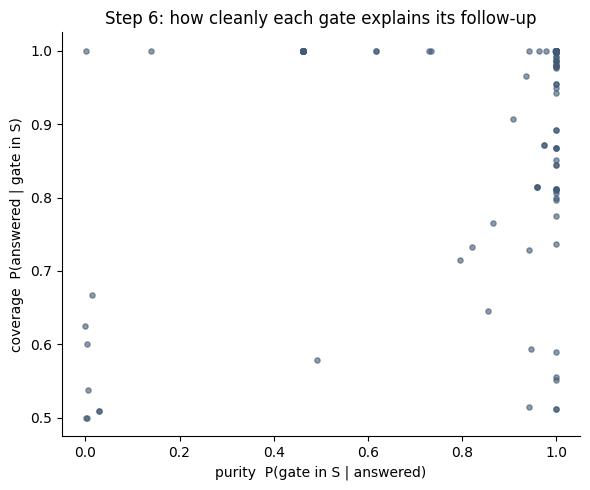

In [3]:
print(f"{len(gates)} high-missing features; gate found for {int(gates.gate.ne('').sum())}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(gates.purity, gates.coverage, s=14, alpha=0.6, color="#405B76")
ax.set_xlabel("purity  P(gate in S | answered)")
ax.set_ylabel("coverage  P(answered | gate in S)")
ax.set_title("Step 6: how cleanly each gate explains its follow-up")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()